### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [1]:
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    !pip install --no-deps unsloth vllm
# Install latest Hugging Face for Gemma-3!
!pip install --no-deps git+https://github.com/huggingface/transformers@v4.49.0-Gemma-3
!pip install bitsandbytes
!pip install unsloth_zoo
!pip install msgspec
!pip install blake3
!pip install gguf
!pip install networkx==2.8.8 --force-reinstall


In [2]:
#@title Colab Extra Install { display-mode: "form" }
%%capture
import os
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth vllm
else:
    !pip install --no-deps unsloth vllm
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    # Skip restarting message in Colab
    import sys, re, requests; modules = list(sys.modules.keys())
    for x in modules: sys.modules.pop(x) if "PIL" in x or "google" in x else None
    !pip install --no-deps bitsandbytes accelerate xformers==0.0.29.post3 peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf datasets huggingface_hub hf_transfer

    # vLLM requirements - vLLM breaks Colab due to reinstalling numpy
    f = requests.get("https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/requirements/common.txt").content
    with open("vllm_requirements.txt", "wb") as file:
        file.write(re.sub(rb"(transformers|numpy|xformers)[^\n]{1,}\n", b"", f))
    !pip install -r vllm_requirements.txt

### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [3]:
%pip uninstall -y Pillow
%pip install --no-cache-dir --force-reinstall "Pillow==11.3.0"
%pip install --no-cache-dir "transformers==5.17.0"

Found existing installation: pillow 13.0.0
Uninstalling pillow-13.0.0:
  Successfully uninstalled pillow-13.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 107.9 MB/s  0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.33.0 requires fastsafetensors>=0.3.3, which is not installed.
vllm 0.33.0 requires flashinfer-python==0.7.2.post1, which is not installed.
vllm 0.33.0 requires humming-kernels[cu13]==0.1.19, which is not installed.
vllm 0.33.0 requires instanttensor>=0.2.2, which is not installed.
vllm 0.33.0 requires nvidia-cudnn-frontend>=1.31.0, which is not installed.
vllm 0.33.0 requires nvidia-cutlass-dsl[cu13]==4.8.0, which is not installed.
vllm 0.33.0 requires PyNvVideoCodec==2.0.4, which is not installed.
vllm 0.33.0 requires quack-kernels==0.6.5, which is not installed.
vllm 0.33.0 requires tilelang==0.1.12, which is not installe

In [4]:

import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)
print("Pillow import successful!")


Pillow version: 11.3.0
Pillow import successful!


In [5]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1111 12:49:26.129000 465 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 12:49:26.219000 465 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 12:49:32.393000 465 torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1111 12:49:32.395000 465 torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1111 12:49:32.400000 465 torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0. vLLM: 0.33.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

We now add LoRA adapters so we only need to update a small amount of parameters!

In [6]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

# Dataset Preparation
## Step 1: Data Inspection

In [7]:

import csv

file_path = "/content/dataasilida_cleaned.csv"

# Read the original CSV without changing it
with open(file_path, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    rows = list(reader)

header = rows[0]
data_rows = rows[1:]

# Check record structure
valid_rows = []
malformed_rows = []

for index, row in enumerate(data_rows, start=2):
    if len(row) == 2:
        valid_rows.append(row)
    else:
        malformed_rows.append((index, row))

print("===== DATASET INSPECTION =====")
print("Header:", header)
print("Total records:", len(data_rows))
print("Valid two-column records:", len(valid_rows))
print("Malformed records:", len(malformed_rows))

print("\n===== FIRST QUESTION =====")
print(valid_rows[0][0])

print("\n===== FIRST ANSWER =====")
print(valid_rows[0][1])

print("\n===== MALFORMED RECORDS =====")
for row_number, row in malformed_rows:
    print(f"CSV record {row_number}:")
    print(str(row)[:160])
    print("-" * 40)


===== DATASET INSPECTION =====
Header: ['input,output']
Total records: 521
Valid two-column records: 514
Malformed records: 7

===== FIRST QUESTION =====
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី

===== FIRST ANSWER =====
ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។

===== MALFORMED RECORDS =====
CSV record 98:
['តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានកំណត់ទំហំទឹកប្រាក់ និងចំនួនប័ណ្ណ ដែរ ឬទេ ? ,លោក-អ្នកអាចបង្កើតប័ណ្ណនិម្មិតអេស៊ីលីដា ដែលមានទំហំប្រតិបត្តិការប្រចាំថ្ងៃរហូតដល់ ៥០០០ដុល
----------------------------------------
CSV record 99:
['តើប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់បានរហូតដល់រយៈពេលប៉ុន្មាន ? ,ប័ណ្ណនិម្មិតអេស៊ីលីដា មានសុពលភាពប្រើប្រាស់ ៣ឆ្នាំ ដោយគិតចាប់ពីថ្ងៃបង្កើត ឬបោះពុម្ព ។']
-----

## Step 2: Repair CSV Structure

In [8]:

import csv

# Input and output file paths
input_file = "/content/dataasilida_cleaned.csv"
output_file = "/content/dataasilida_repaired.csv"

records = []
repaired_count = 0

# 1. Read the original dataset
with open(input_file, "r", encoding="utf-8-sig", newline="") as f:
    reader = csv.reader(f)
    next(reader)  # Skip incorrect header

    for row in reader:
        if len(row) == 2:
            question, answer = row

        elif len(row) == 1:
            text = row[0]

            if "," in text:
                question, answer = text.split(",", 1)

            elif "?" in text:
                question, answer = text.split("?", 1)
                question += "?"

            else:
                raise ValueError(f"Cannot repair: {row}")

            repaired_count += 1

        else:
            raise ValueError(f"Unexpected row: {row}")

        records.append([
            question.strip(),
            answer.strip()
        ])

# 2. Save the repaired dataset
with open(output_file, "w", encoding="utf-8-sig", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["input", "output"])
    writer.writerows(records)

# 3. Verify the result
assert len(records) == 521
assert repaired_count == 7

print("Dataset repaired successfully!")
print("Total records:", len(records))
print("Repaired records:", repaired_count)
print("Saved to:", output_file)


Dataset repaired successfully!
Total records: 521
Repaired records: 7
Saved to: /content/dataasilida_repaired.csv


In [9]:
# verify the repaired dataset

from datasets import load_dataset

dataset = load_dataset(
    "csv",
    data_files="/content/dataasilida_repaired.csv"
)

print(dataset)
print(dataset["train"].column_names)
print(dataset["train"][0])

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 521
    })
})
['input', 'output']
{'input': 'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី', 'output': 'ប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។'}


## Step 3: Check Missing Values, Duplicates, and Conflicting Answers

In [10]:

import pandas as pd

# Convert Hugging Face dataset to DataFrame
df = dataset["train"].to_pandas()

print("===== DATASET QUALITY CHECK =====")

# 1. Check missing values
missing = df.isna().sum()
empty = (df.fillna("").apply(
    lambda col: col.str.strip() == ""
)).sum()

print("\n1. Missing values:")
print(missing)

print("\nEmpty strings:")
print(empty)

# 2. Check exact duplicate question-answer pairs
duplicates = df.duplicated(
    subset=["input", "output"]
).sum()

print("\n2. Exact duplicate records:", duplicates)

# 3. Check questions with multiple different answers
conflicts = (
    df.groupby("input")["output"]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

print("\n3. Questions with multiple answers:",
      len(conflicts))

# 4. Display examples for review
for question in conflicts.index[:5]:
    print("\nQuestion:", question)

    answers = df.loc[
        df["input"] == question, "output"
    ].unique()

    for i, answer in enumerate(answers, start=1):
        print(f"Answer {i}: {answer[:200]}...")


===== DATASET QUALITY CHECK =====

1. Missing values:
input     0
output    0
dtype: int64

Empty strings:
input     0
output    0
dtype: int64

2. Exact duplicate records: 2

3. Questions with multiple answers: 16

Question: ដើម្បីបើកគណនីក្រុមហ៊ុន ឬស្ថាប័ន បានត្រូវមានឯកសារអ្វីខ្លះ
Answer 1: ត្រូវមានឯកសារដូចខាងក្រោម៖ \n អនុស្សរណៈ និងលក្ខន្តិកៈ វិញ្ញាបនបត្រចុះបញ្ជីពាណិជ្ជកម្ម ភាពជាដៃគូ ដែលសមស្របតាមសភាពជាក់ស្តែង ។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់ម្ចាស់គណនី \n លិខិតអនុញ្ញាតអាជីវកម្ម ឬឲ្យដំណើរកា...
Answer 2: ត្រូវមានឯកសារដូចខាងក្រោម៖ \n អនុស្សរណៈ និងលក្ខន្តិកៈ វិញ្ញាបនបត្រចុះបញ្ជីពាណិជ្ជកម្ម ភាពជាដៃគូ ដែលសមស្របតាមសភាពជាក់ស្តែង។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់ម្ចាស់គណនី \n លិខិតអនុញ្ញាតអាជីកម្ម ឬឲ្យដំណើរការអ...
Answer 3: ត្រូវមានឯកសារដូចខាងក្រោម៖ \n អនុស្សរណៈ និងលក្ខន្តិកៈ វិញ្ញាបនបត្រចុះបញ្ជីពាណិជ្ជកម្ម ភាពជាដៃគូ ដែលសមស្របតាមសភាពជាក់ស្តែង ។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់ម្ចាស់គណនី \n លិខិតអនុញ្ញាតអាជីកម្ម ឬឲ្យដំណើរការ...

Question: ដើម្បីបើកគណនីជនបរទេសបានត្រូវមានឯកសារអ្វីខ្លះ
Answer 1: ត្រូវមានឯ

In [11]:
# Remove exact duplicates


import pandas as pd

# Use the dataset from Step 3
df = dataset["train"].to_pandas().copy()

# Remove leading/trailing spaces
df["input"] = df["input"].str.strip()
df["output"] = df["output"].str.strip()

# Remove only exact duplicate pairs
df_clean = df.drop_duplicates(
    subset=["input", "output"],
    keep="first"
).reset_index(drop=True)

print("Original records:", len(df))
print("After removing duplicates:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

# Save the result
df_clean.to_csv(
    "/content/dataasilida_deduplicated.csv",
    index=False,
    encoding="utf-8-sig"
)


Original records: 521
After removing duplicates: 519
Duplicates removed: 2


In [12]:
# Create a conflict review file


# Find questions with multiple distinct answers
answer_counts = (
    df_clean.groupby("input")["output"].nunique()
)

conflict_questions = answer_counts[
    answer_counts > 1
].index

# Collect all affected records
review_df = df_clean[
    df_clean["input"].isin(conflict_questions)
].copy()

# Sort records by question
review_df = review_df.sort_values("input")

# Add review fields
review_df["review_status"] = "needs_review"
review_df["review_note"] = ""

# Save for manual review
review_df.to_csv(
    "/content/conflicting_answers_review.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Questions needing review:", len(conflict_questions))
print("Records needing review:", len(review_df))
print("Review file saved successfully!")


Questions needing review: 16
Records needing review: 54
Review file saved successfully!


In [13]:
# Prepare the unambiguous records

df_unambiguous = df_clean[
    ~df_clean["input"].isin(conflict_questions)
].copy()

df_unambiguous.to_csv(
    "/content/dataasilida_unambiguous.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Unambiguous records:", len(df_unambiguous))
print("Records awaiting review:", len(review_df))

Unambiguous records: 465
Records awaiting review: 54


In [14]:
# Review conflicting questions


import pandas as pd

review_df = pd.read_csv(
    "/content/conflicting_answers_review.csv"
)

# Get all questions that need review
questions = review_df["input"].unique()

print("Questions to review:", len(questions))

# Show the first conflicting question
question = questions[0]

matches = review_df[
    review_df["input"] == question
]

print("\nQUESTION:")
print(question)

for i, answer in enumerate(matches["output"], 1):
    print(f"\nANSWER {i}:")
    print(answer)
    print("-" * 50)


Questions to review: 16

QUESTION:
ដើម្បីបើកគណនីក្រុមហ៊ុន ឬស្ថាប័ន បានត្រូវមានឯកសារអ្វីខ្លះ

ANSWER 1:
ត្រូវមានឯកសារដូចខាងក្រោម៖ \n អនុស្សរណៈ និងលក្ខន្តិកៈ វិញ្ញាបនបត្រចុះបញ្ជីពាណិជ្ជកម្ម ភាពជាដៃគូ ដែលសមស្របតាមសភាពជាក់ស្តែង ។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់ម្ចាស់គណនី \n លិខិតអនុញ្ញាតអាជីវកម្ម ឬឲ្យដំណើរការអង្គភាព \n ប័ណ្ណប៉ាតង់ វិញ្ញាបនបត្រចុះបញ្ជីអាករលើតម្លៃបន្ថែម លិខិតបញ្ជាក់ការបង់ប្រាក់ពន្ធ ឬលិខិតប្រកាសពន្ធផ្សេងៗ ដែលមានលិខិតអត្តសញ្ញាណកម្មសារពើពន្ធ ។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់នាយក ភាគទុនិក ឬដៃគូ \n សេចក្តីសម្រេចចិត្តរបស់ក្រុមប្រឹក្សាភិបាល ឬនាយកគ្រប់គ្រង លើការបើកគណនី \n លិខិតផ្ទេរសិទ្ធិដល់បុគ្គលណាម្នាក់ជាតំណាងឲ្យក្រុមហ៊ុន ឬអាជីវកម្ម \n ឯកសារពាក់ព័ន្ធផ្សេងៗទៀត ។
--------------------------------------------------

ANSWER 2:
ត្រូវមានឯកសារដូចខាងក្រោម៖ \n អនុស្សរណៈ និងលក្ខន្តិកៈ វិញ្ញាបនបត្រចុះបញ្ជីពាណិជ្ជកម្ម ភាពជាដៃគូ ដែលសមស្របតាមសភាពជាក់ស្តែង។ \n ឯកសារសម្គាល់អត្តសញ្ញាណរបស់ម្ចាស់គណនី \n លិខិតអនុញ្ញាតអាជីកម្ម ឬឲ្យដំណើរការអង្គភាព \n ប័ណ្ណប៉ាតង់ វិញ្ញាបនបត្រចុះបញ្ជីអាករលើតំលៃបន្ថែម លិខិតបញ្

In [15]:
# Split the dataset into Training, validation, and testing set

from datasets import load_dataset, DatasetDict

dataset = load_dataset(
    "csv",
    data_files="/content/dataasilida_unambiguous.csv"
)

split1 = dataset["train"].train_test_split(
    test_size=0.2,
    seed=3407
)

split2 = split1["test"].train_test_split(
    test_size=0.5,
    seed=3407
)

dataset = DatasetDict({
    "train": split1["train"],
    "validation": split2["train"],
    "test": split2["test"]
})

print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 372
    })
    validation: Dataset({
        features: ['input', 'output'],
        num_rows: 46
    })
    test: Dataset({
        features: ['input', 'output'],
        num_rows: 47
    })
})


In [16]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [17]:
# Check the dataset

print(dataset["train"].column_names)
print(dataset["train"][0])

['input', 'output']
{'input': 'តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស', 'output': '\\nមានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ \\n ចំណេញពេលវេលា។ \\n អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។'}


In [18]:
print("Question:", dataset["train"]["input"][0])
print("Answer:", dataset["train"]["output"][0])

Question: តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស
Answer: \nមានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ \n ចំណេញពេលវេលា។ \n អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។


In [19]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      #tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      texts.append(text)
    return {"text":texts}



In [20]:
dataset = dataset.map(
    formatting_prompts_func,
    batched=True
)

print(dataset)

Map:   0%|          | 0/372 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

Map:   0%|          | 0/47 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 372
    })
    validation: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 46
    })
    test: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 47
    })
})


In [21]:
print(dataset["train"][0]["text"])

<bos><start_of_turn>user
តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស<end_of_turn>
<start_of_turn>model
\nមានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ \n ចំណេញពេលវេលា។ \n អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។<end_of_turn>



In [22]:
answer = dataset["train"][0]["output"]

print("Literal \\n:", r"\n" in answer)
print("Actual newline:", "\n" in answer)

Literal \n: True
Actual newline: False


In [23]:
# If Literal \n is True, clean it:

def clean_newlines(example):
    example["output"] = (
        example["output"]
        .replace(r"\n", "\n")
        .strip()
    )
    return example

dataset = dataset.map(clean_newlines)

# Regenerate formatted text after cleaning
dataset = dataset.map(
    formatting_prompts_func,
    batched=True
)

Map:   0%|          | 0/372 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

Map:   0%|          | 0/47 [00:00<?, ? examples/s]

Map:   0%|          | 0/372 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

Map:   0%|          | 0/47 [00:00<?, ? examples/s]

In [24]:
for split in ["train", "validation", "test"]:
    print(
        split,
        len(dataset[split]),
        dataset[split].column_names
    )

train 372 ['input', 'output', 'text']
validation 46 ['input', 'output', 'text']
test 47 ['input', 'output', 'text']


In [25]:
print(dataset["train"].column_names)
print(dataset["train"]["text"][0])

['input', 'output', 'text']
<bos><start_of_turn>user
តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស<end_of_turn>
<start_of_turn>model
មានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ 
 ចំណេញពេលវេលា។ 
 អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។<end_of_turn>



Let's see how row 100 looks like!

In [26]:
dataset['train']['input'][99]

'ហេតុអ្វីបានជាលោក-អ្នក ជ្រើសរើសក្នុងការប្រើប្រាស់សេវាអេស៊ីលីដាម៉ូបាល'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [27]:
dataset['train']['output'][99]

'សេវាអេស៊ីលីដាម៉ូបាល គឺជាសេវាដែលមានភាពងាយស្រួល និងមានសុវត្ថិភាពខ្ពស់ក្នុងការប្រើប្រាស់ ។'

In [28]:
# Check current environment

import importlib.metadata as metadata

for package in ["unsloth", "trl", "transformers", "peft"]:
    print(package, metadata.version(package))

unsloth 2026.11.3
trl 1.15.0
transformers 5.17.0
peft 0.21.2


<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

In [31]:
# from trl import SFTTrainer, SFTConfig
# trainer = SFTTrainer(
#     model = model,
#     tokenizer = tokenizer,
#     train_dataset = dataset,
#     eval_dataset = None, # Can set up evaluation!
#     args = SFTConfig(
#         dataset_text_field = "text",
#         per_device_train_batch_size = 2,
#         gradient_accumulation_steps = 4, # Use GA to mimic batch size!
#         warmup_steps = 5,
#         # num_train_epochs = 1, # Set this for 1 full training run.
#         max_steps = 60,
#         learning_rate = 2e-4, # Reduce to 2e-5 for long training runs
#         logging_steps = 1,
#         optim = "adamw_8bit",
#         weight_decay = 0.01,
#         lr_scheduler_type = "linear",
#         seed = 3407,
#         report_to = "none", # Use this for WandB etc
#     ),
# )

In [34]:
# Configure Experiment A (Baseline)


from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported

# Experiment A configuration
training_config = SFTConfig(
    output_dir="outputs_experiment_A",

    # Training settings
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    max_steps=60,
    warmup_steps=5,

    # Validation settings
    eval_strategy="steps",
    eval_steps=10,
    per_device_eval_batch_size=1,

    # Optimization
    optim="adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="linear",

    # Precision
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),

    # Dataset settings
    dataset_text_field="text",
    max_length=2048,
    packing=False,

    # Logging
    logging_steps=1,
    seed=3407,
    report_to="none",
    save_strategy="no",
)

print("Experiment A configuration created!")
print("Learning rate:", training_config.learning_rate)
print("Training steps:", training_config.max_steps)
print("Validation every:", training_config.eval_steps, "steps")


Experiment A configuration created!
Learning rate: 0.0002
Training steps: 60
Validation every: 10 steps


In [35]:
# Initialize SFTTrainer

from trl import SFTTrainer

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    args=training_config,
)

print("SFTTrainer initialized successfully!")
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/372 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/46 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
SFTTrainer initialized successfully!
Training examples: 372
Validation examples: 46


In [36]:
from unsloth.chat_templates import train_on_responses_only

trainer = train_on_responses_only(
    trainer,
    instruction_part="<start_of_turn>user\n",
    response_part="<start_of_turn>model\n",
)

Map:   0%|          | 0/372 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

In [37]:

for split_name, data in [
    ("Training", trainer.train_dataset),
    ("Validation", trainer.eval_dataset),
]:
    sample = data[0]

    if "labels" not in sample:
        raise ValueError(
            f"{split_name} labels are missing!"
        )

    labels = sample["labels"]

    # -100 means the token is ignored by the loss
    active_tokens = sum(
        token != -100 for token in labels
    )

    print(f"{split_name} active answer tokens:",
          active_tokens)

    assert active_tokens > 0, (
        f"No active answer tokens in {split_name}!"
    )

print("\nLabel verification completed!")


Training active answer tokens: 46
Validation active answer tokens: 157

Label verification completed!


In [38]:
sample = trainer.train_dataset[0]

answer_ids = [
    token
    for token in sample["labels"]
    if token != -100
]

print(tokenizer.decode(
    answer_ids,
    skip_special_tokens=True
))

មានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ 
 ចំណេញពេលវេលា។ 
 អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។


In [39]:

# Experiment A: Fine-tuning Gemma 3 (4B)

trainer_stats = trainer.train()

print("Experiment A training completed!")
print("Training loss:", trainer_stats.training_loss)


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 372 | Num Epochs = 2 | Total steps = 60
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,1.967401,1.962583
20,1.821623,1.599899
30,1.654587,1.496479
40,1.517252,1.459790
50,1.331573,1.435062
60,1.625489,1.416678


Filter:   0%|          | 0/46 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


Experiment A training completed!
Training loss: 1.7769931306441624


In [40]:
# Save the loss result


import pandas as pd

history = pd.DataFrame(trainer.state.log_history)

# Save all training and validation logs
history.to_csv(
    "/content/experiment_A_loss_history.csv",
    index=False
)

print("Training and validation history:")
print(history.to_string(index=False))


Training and validation history:
    loss  grad_norm  learning_rate    epoch  step  eval_loss  eval_runtime  eval_samples_per_second  eval_steps_per_second  train_runtime  train_samples_per_second  train_steps_per_second   total_flos  train_loss
2.738028   1.992805       0.000000 0.021505     1        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN          NaN         NaN
3.354058   2.691827       0.000040 0.043011     2        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN          NaN         NaN
3.788497   2.840390       0.000080 0.064516     3        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN          NaN         NaN
3.422096   2.675368       0.000120 0.086022     4        NaN           NaN                      NaN                

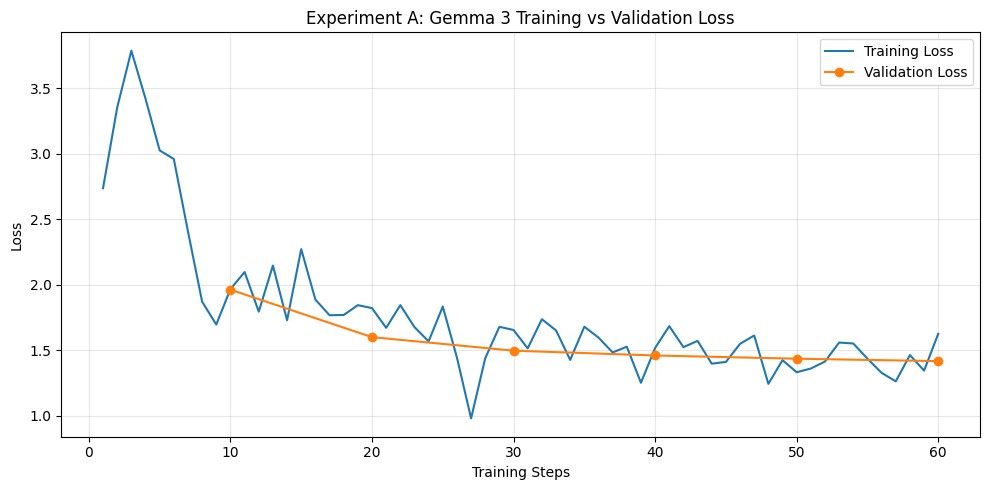

In [41]:
# plot the loss graph


import matplotlib.pyplot as plt

train_log = history.dropna(subset=["loss"])
val_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(10, 5))

plt.plot(
    train_log["step"],
    train_log["loss"],
    label="Training Loss"
)

plt.plot(
    val_log["step"],
    val_log["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Experiment A: Gemma 3 Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/experiment_A_loss_curve.png",
    dpi=200
)

plt.show()


In [42]:

# Save Experiment A LoRA adapters and tokenizer

save_path = "/content/gemma3_experiment_A"

trainer.model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Experiment A saved successfully!")
print("Location:", save_path)


Unsloth: Restored added_tokens_decoder metadata in /content/gemma3_experiment_A/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gemma3_experiment_A.


Experiment A saved successfully!
Location: /content/gemma3_experiment_A


## Experiment B: Change the Learning Rate 1.5e-4

In [43]:
# Clear Experiment A from GPU memory


import gc
import torch

# Remove previous model and trainer from memory
for name in ["trainer", "model", "trainer_stats"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared!")


GPU memory cleared!


In [44]:
# Load a fresh Gemma 3 (4B) model


from unsloth import FastModel
from unsloth.chat_templates import get_chat_template

model, tokenizer = FastModel.from_pretrained(
    model_name="unsloth/gemma-3-4b-it",
    max_seq_length=2048,
    load_in_4bit=True,
    load_in_8bit=False,
    full_finetuning=False,
)

# Apply fresh LoRA adapters
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=8,
    lora_alpha=8,
    lora_dropout=0,
    bias="none",
    random_state=3407,
)

tokenizer = get_chat_template(
    tokenizer,
    chat_template="gemma-3",
)

print("Fresh Gemma 3 model loaded!")
print("Experiment B model ready!")


==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0. vLLM: 0.33.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [45]:
# Experiment B using Learning rate = 1.5e-4


from trl import SFTConfig
from unsloth import is_bfloat16_supported

training_config_B = SFTConfig(
    output_dir="outputs_experiment_B",

    # Same settings as Experiment A
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    max_steps=60,
    warmup_steps=5,

    # Only modified hyperparameter
    learning_rate=1.5e-4,

    # Validation
    eval_strategy="steps",
    eval_steps=10,
    per_device_eval_batch_size=1,

    # Optimization
    optim="adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="linear",

    # Precision
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),

    # Dataset
    dataset_text_field="text",
    max_length=2048,
    packing=False,

    # Logging
    logging_steps=1,
    seed=3407,
    report_to="none",
    save_strategy="no",
)

print("Experiment B configuration created!")
print("Learning rate:", training_config_B.learning_rate)
print("Training steps:", training_config_B.max_steps)
print("Validation every:", training_config_B.eval_steps)


Unsloth: not enough free memory for dataset tokenization workers (~1GB each); tokenizing in-process.
Experiment B configuration created!
Learning rate: 0.00015
Training steps: 60
Validation every: 10


In [46]:
# Initialize SFTTrainer for Experiment B


from trl import SFTTrainer

trainer_B = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    args=training_config_B,
)

print("Experiment B SFTTrainer initialized!")
print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.
Unsloth: We found double BOS tokens - we shall remove one automatically.
🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Experiment B SFTTrainer initialized!
Training examples: 372
Validation examples: 46


In [47]:

from unsloth.chat_templates import train_on_responses_only

trainer_B = train_on_responses_only(
    trainer_B,
    instruction_part="<start_of_turn>user\n",
    response_part="<start_of_turn>model\n",
)

print("Experiment B response-only training configured!")


Experiment B response-only training configured!


In [48]:

for split_name, data in [
    ("Training", trainer_B.train_dataset),
    ("Validation", trainer_B.eval_dataset),
]:
    active_counts = [
        sum(token != -100 for token in sample["labels"])
        for sample in data
    ]

    print(
        f"{split_name}:",
        len(active_counts),
        "examples"
    )
    print(
        "Examples with valid answer tokens:",
        sum(count > 0 for count in active_counts)
    )

    assert all(count > 0 for count in active_counts), (
        f"{split_name} contains examples with no answer tokens!"
    )

print("\nExperiment B label verification completed!")


Training: 372 examples
Examples with valid answer tokens: 372
Validation: 46 examples
Examples with valid answer tokens: 46

Experiment B label verification completed!


In [49]:
# Train Experiment B

trainer_stats_B = trainer_B.train()

print("Experiment B completed!")
print("Training loss:", trainer_stats_B.training_loss)

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 372 | Num Epochs = 2 | Total steps = 60
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,1.956061,1.914443
20,1.912965,1.681554
30,1.683697,1.545384
40,1.549595,1.486838
50,1.393735,1.477009
60,1.693083,1.467071


Experiment B completed!
Training loss: 1.8346234540144601


In [50]:

# Save Experiment B adapters
save_path_B = "/content/gemma3_experiment_B"

trainer_B.model.save_pretrained(save_path_B)
tokenizer.save_pretrained(save_path_B)

print("Experiment B saved successfully!")
print("Location:", save_path_B)


Unsloth: Restored added_tokens_decoder metadata in /content/gemma3_experiment_B/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gemma3_experiment_B.


Experiment B saved successfully!
Location: /content/gemma3_experiment_B


In [51]:

import pandas as pd

history_B = pd.DataFrame(
    trainer_B.state.log_history
)

history_B.to_csv(
    "/content/experiment_B_loss_history.csv",
    index=False
)

print("Experiment B loss history saved!")
print(
    history_B[
        ["step", "loss", "eval_loss"]
    ].dropna(
        how="all",
        subset=["loss", "eval_loss"]
    ).to_string(index=False)
)


Experiment B loss history saved!
 step     loss  eval_loss
    1 2.738028        NaN
    2 3.354058        NaN
    3 3.798788        NaN
    4 3.470029        NaN
    5 3.142895        NaN
    6 3.141152        NaN
    7 2.686910        NaN
    8 2.039050        NaN
    9 1.838720        NaN
   10 1.956061        NaN
   10      NaN   1.914443
   11 2.037263        NaN
   12 1.758030        NaN
   13 2.178795        NaN
   14 1.782734        NaN
   15 2.386835        NaN
   16 2.017397        NaN
   17 1.843508        NaN
   18 1.849372        NaN
   19 1.935304        NaN
   20 1.912965        NaN
   20      NaN   1.681554
   21 1.765389        NaN
   22 1.934915        NaN
   23 1.737561        NaN
   24 1.624639        NaN
   25 1.905171        NaN
   26 1.482302        NaN
   27 1.008814        NaN
   28 1.467989        NaN
   29 1.720536        NaN
   30 1.683697        NaN
   30      NaN   1.545384
   31 1.548443        NaN
   32 1.807869        NaN
   33 1.687723        NaN
   34

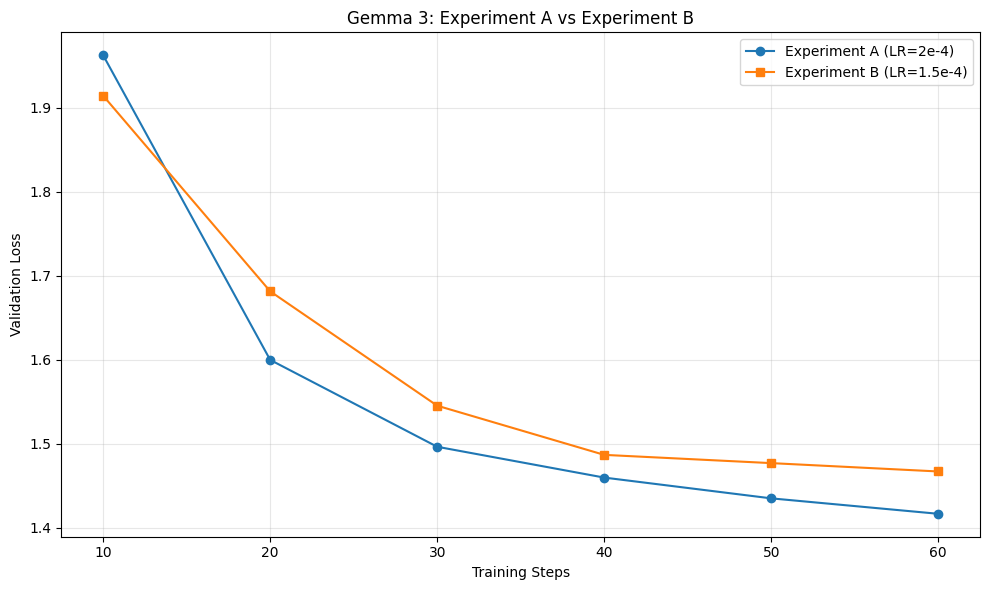

In [52]:

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load Experiment A's recorded results
path_A = "/content/experiment_A_loss_history.csv"

if not os.path.exists(path_A):
    raise FileNotFoundError(
        "Upload experiment_A_loss_history.csv "
        "to Colab before running this cell."
    )

history_A = pd.read_csv(path_A)

# Load Experiment B

history_B = pd.read_csv(
    "/content/experiment_B_loss_history.csv"
)

val_A = history_A.dropna(subset=["eval_loss"])
val_B = history_B.dropna(subset=["eval_loss"])

plt.figure(figsize=(10, 6))

plt.plot(
    val_A["step"],
    val_A["eval_loss"],
    marker="o",
    label="Experiment A (LR=2e-4)"
)

plt.plot(
    val_B["step"],
    val_B["eval_loss"],
    marker="s",
    label="Experiment B (LR=1.5e-4)"
)

plt.xlabel("Training Steps")
plt.ylabel("Validation Loss")
plt.title("Gemma 3: Experiment A vs Experiment B")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/experiment_comparison.png",
    dpi=200
)

plt.show()


## Experiment C - Combined Tuning

In [53]:

import gc
import torch

for name in [
    "trainer", "trainer_B", "model",
    "trainer_stats_B",
]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared!")


GPU cache cleared!


In [54]:

from unsloth import FastModel
from unsloth.chat_templates import get_chat_template

# Load original Gemma 3 model
model, tokenizer = FastModel.from_pretrained(
    model_name="unsloth/gemma-3-4b-it",
    max_seq_length=2048,
    load_in_4bit=True,
    load_in_8bit=False,
    full_finetuning=False,
)

# Experiment C: New LoRA configuration
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,

    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    random_state=3407,
)

tokenizer = get_chat_template(
    tokenizer,
    chat_template="gemma-3",
)

print("Experiment C model loaded!")

for name, config in model.peft_config.items():
    print("LoRA rank:", config.r)
    print("LoRA alpha:", config.lora_alpha)
    print("LoRA dropout:", config.lora_dropout)


==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0. vLLM: 0.33.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [55]:

from trl import SFTConfig
from unsloth import is_bfloat16_supported

training_config_C = SFTConfig(
    output_dir="/content/outputs_experiment_C",

    # Batch configuration
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=1,

    # Learning configuration
    learning_rate=1e-4,
    max_steps=184,
    warmup_steps=10,

    # Optimization
    optim="adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="cosine",
    max_grad_norm=1.0,

    # Validation
    eval_strategy="steps",
    eval_steps=10,

    # Precision
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),

    # Dataset
    dataset_text_field="text",
    max_length=2048,
    packing=False,

    # Logging and reproducibility
    logging_steps=1,
    seed=3407,
    report_to="none",
    save_strategy="steps",
    save_steps=10,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

print("Experiment C configuration:")
print("Learning rate:", training_config_C.learning_rate)
print("Max steps:", training_config_C.max_steps)
print("Batch size:", training_config_C.per_device_train_batch_size)
print("Gradient accumulation:", training_config_C.gradient_accumulation_steps)
print("Weight decay:", training_config_C.weight_decay)
print("Scheduler:", training_config_C.lr_scheduler_type)


Experiment C configuration:
Learning rate: 0.0001
Max steps: 184
Batch size: 2
Gradient accumulation: 4
Weight decay: 0.01
Scheduler: SchedulerType.COSINE


In [56]:

from trl import SFTTrainer
from unsloth.chat_templates import train_on_responses_only

trainer_C = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    args=training_config_C,
)

trainer_C = train_on_responses_only(
    trainer_C,
    instruction_part="<start_of_turn>user\n",
    response_part="<start_of_turn>model\n",
)

# Check every training and validation example
for name, data in [
    ("Training", trainer_C.train_dataset),
    ("Validation", trainer_C.eval_dataset),
]:
    active = [
        sum(label != -100 for label in row["labels"])
        for row in data
    ]

    assert all(n > 0 for n in active), (
        f"{name} contains fully masked examples"
    )

    print(name, "verified:", len(data))

print("Experiment C is ready!")


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.
Unsloth: We found double BOS tokens - we shall remove one automatically.
🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Training verified: 372
Validation verified: 46
Experiment C is ready!


In [57]:

trainer_stats_C = trainer_C.train()

print("Experiment C completed!")
print(
    "Average training loss:",
    trainer_stats_C.training_loss
)


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 372 | Num Epochs = 4 | Total steps = 184
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,802,496 of 4,329,881,968 (0.69% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,1.939841,1.903227
20,1.816313,1.578699
30,1.609190,1.447054
40,1.452762,1.412281
50,1.150607,1.334945
60,1.514185,1.293756
70,1.202297,1.271930
80,1.212466,1.264981
90,1.170192,1.232837
100,1.021422,1.213042


Unsloth: Restored added_tokens_decoder metadata in /content/outputs_experiment_C/checkpoint-10/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/outputs_experiment_C/checkpoint-10.
Unsloth: Restored added_tokens_decoder metadata in /content/outputs_experiment_C/checkpoint-20/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/outputs_experiment_C/checkpoint-20.
Unsloth: Restored added_tokens_decoder metadata in /content/outputs_experiment_C/checkpoint-30/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/outputs_experiment_C/checkpoint-30.
Unsloth: Restored added_tokens_decoder metadata in /content/outputs_experiment_C/checkpoint-40/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/outputs_experiment_C/checkpoint-40.
Unsloth: Restored added_tokens_decoder metadata in /content/outputs_experiment_C/checkpoint-50/tokenizer_con

Experiment C completed!
Average training loss: 1.2501554346602897


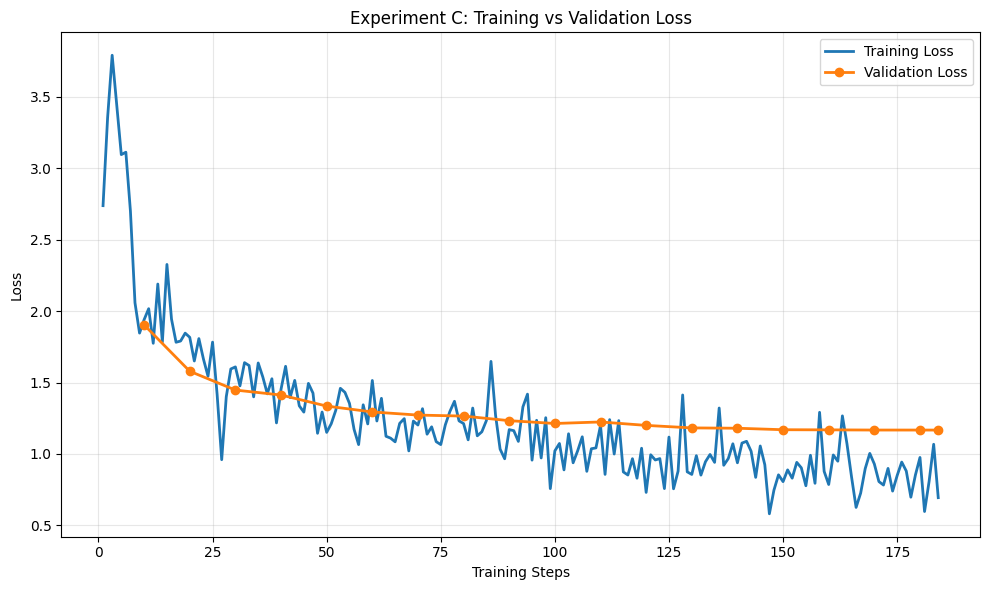

Final validation loss: 1.1670345067977905
Best validation loss: 1.1670345067977905
Best step: 184


In [58]:

import pandas as pd
import matplotlib.pyplot as plt

history_C = pd.DataFrame(
    trainer_C.state.log_history
)

history_C.to_csv(
    "/content/experiment_C_loss_history.csv",
    index=False
)

train_C = history_C.dropna(subset=["loss"])
val_C = history_C.dropna(subset=["eval_loss"])

plt.figure(figsize=(10, 6))

plt.plot(
    train_C["step"],
    train_C["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    val_C["step"],
    val_C["eval_loss"],
    label="Validation Loss",
    marker="o",
    linewidth=2
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Experiment C: Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/experiment_C_loss_curve.png",
    dpi=200
)

plt.show()

best = val_C.loc[val_C["eval_loss"].idxmin()]

print("Final validation loss:", val_C["eval_loss"].iloc[-1])
print("Best validation loss:", best["eval_loss"])
print("Best step:", int(best["step"]))


In [59]:
import pandas as pd

history_C = pd.DataFrame(trainer_C.state.log_history)

history_C.to_csv(
    "/content/experiment_C_loss_history.csv",
    index=False
)

print(
    history_C.dropna(subset=["eval_loss"])[
        ["step", "eval_loss"]
    ]
)

     step  eval_loss
10     10   1.903227
21     20   1.578699
32     30   1.447054
43     40   1.412281
54     50   1.334945
65     60   1.293756
76     70   1.271930
87     80   1.264981
98     90   1.232837
109   100   1.213042
120   110   1.223751
131   120   1.199737
142   130   1.182140
153   140   1.179819
164   150   1.169366
175   160   1.168481
186   170   1.167155
197   180   1.167072
202   184   1.167035


In [60]:

print("===== EXPERIMENT C SETTINGS =====")

print("Learning rate:", trainer_C.args.learning_rate)
print("Max steps:", trainer_C.args.max_steps)

for name, config in trainer_C.model.peft_config.items():
    print("LoRA rank:", config.r)
    print("LoRA alpha:", config.lora_alpha)

print("Training examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))


===== EXPERIMENT C SETTINGS =====
Learning rate: 0.0001
Max steps: 184
LoRA rank: 16
LoRA alpha: 32
Training examples: 372
Validation examples: 46


In [61]:

# Save Experiment C
save_path_C = "/content/gemma3_experiment_C"

trainer_C.model.save_pretrained(save_path_C)
tokenizer.save_pretrained(save_path_C)

print("Experiment C saved successfully!")
print("Location:", save_path_C)


Unsloth: Restored added_tokens_decoder metadata in /content/gemma3_experiment_C/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/gemma3_experiment_C.


Experiment C saved successfully!
Location: /content/gemma3_experiment_C


In [62]:
results = trainer_C.evaluate()

print("Final validation metrics:")
print(results)

Training Loss,Validation Loss,Step
0.693691,1.167035,184


Final validation metrics:
{'eval_loss': 1.1670345067977905}


In [66]:

import torch
import pandas as pd

# Use the latest fine-tuned Experiment C model
model_C = trainer_C.model
model_C.eval()

results = []

# Preview five validation questions
samples = dataset["validation"].select(range(5))

for i, sample in enumerate(samples):

    question = sample["input"]
    expected = sample["output"]

    # Format the question for Gemma 3
    messages = [
        {"role": "user", "content": question}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(model_C.device)

    # Generate answer
    with torch.inference_mode():
        outputs = model_C.generate(
            **inputs,
            max_new_tokens=512,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    # Remove prompt tokens from output
    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    predicted = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    results.append({
        "question": question,
        "expected": expected,
        "predicted": predicted
    })

    print("=" * 70)
    print(f"QUESTION {i+1}:")
    print(question)

    print("\nEXPECTED ANSWER:")
    print(expected)

    print("\nMODEL ANSWER:")
    print(predicted)
    print()

# Save preview results
results_df = pd.DataFrame(results)

results_df.to_csv(
    "/content/experiment_C_validation_preview.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Validation preview completed!")


QUESTION 1:
តើប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា ជាអ្វី

EXPECTED ANSWER:
ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមម៉ាស៊ីន អេធីអឹម (ATM) នៅក្នុងប្រទេស កម្ពុជា ឡាវ និងតាមម៉ាស៊ីនឆូតកាតរបស់ ធនាគារ អេស៊ីលីដា ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅ ធនាគារ អេស៊ីលីដា។

MODEL ANSWER:
ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណឥណពន្ធចរន្ត (Cheque Card) ដែលមានលក្ខណៈពិសេស ដែលអនុញ្ញាតឲ្យអតិថិជនអាចប្រើប្រាស់បានគ្រប់ម៉ាស៊ីន អេធីអឹម របស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី គ្រប់ទូទាំងប្រទេស និងក្រៅប្រទេស ក្នុងការទូទាត់សាច់ប្រាក់ ឬទូទាត់ថ្លៃទំនិញផ្សេងៗ។

QUESTION 2:
តើអតិថិជនអាចផ្ទេរប្រាក់បានយ៉ាងដូចម្តេចខ្លះ

EXPECTED ANSWER:
អាចផ្ទេរពីអ្នកគ្មានគណនី ទៅអ្នកគ្មានគណនីដូចគ្នា 
 អាចផ្ទេរពីអ្នកគ្មានគណនី ទៅអ្នកមានគណនី 
 អាចផ្ទេរពីអ្នកមានគណនី ទៅអ្នកមានគណនីដូចគ្នា 
 អាចផ្ទេរពីធនាគារអេស៊ីលីដា ទៅធនាគារផ្សេង ឬផ្ទុយមកវិញ។

MODEL ANSWER:
អតិថិជនអាចផ្ទេរប្រាក់ទៅគណនីផ្សេងៗ ដូចជា៖ គណនីធនាគារ អេស៊ីលីដា គណនីធនាគារឯកទេស អេ

In [67]:

import torch
import pandas as pd

model_C = trainer_C.model
model_C.eval()

new_results = []

for i, sample in enumerate(
    dataset["validation"].select(range(5))
):
    question = sample["input"]
    expected = sample["output"]

    messages = [
        {"role": "user", "content": question}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(model_C.device)

    with torch.inference_mode():
        outputs = model_C.generate(
            **inputs,

            # New generation settings
            max_new_tokens=256,
            do_sample=False,
            repetition_penalty=1.1,
            no_repeat_ngram_size=5,

            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    prediction = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    new_results.append({
        "question": question,
        "expected": expected,
        "prediction": prediction,
        "generated_tokens": len(generated_tokens),
        "hit_token_limit": len(generated_tokens) == 256
    })

    print("=" * 65)
    print(f"QUESTION {i+1}: {question}")

    print("\nEXPECTED:")
    print(expected)

    print("\nNEW MODEL ANSWER:")
    print(prediction)

    print("\nGenerated tokens:", len(generated_tokens))
    print("Hit token limit:", len(generated_tokens) == 256)

results_new = pd.DataFrame(new_results)

results_new.to_csv(
    "/content/experiment_C_decoding_test.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDecoding experiment completed!")


QUESTION 1: តើប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា ជាអ្វី

EXPECTED:
ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមម៉ាស៊ីន អេធីអឹម (ATM) នៅក្នុងប្រទេស កម្ពុជា ឡាវ និងតាមម៉ាស៊ីនឆូតកាតរបស់ ធនាគារ អេស៊ីលីដា ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅ ធនាគារ អេស៊ីលីដា។

NEW MODEL ANSWER:
ប័ណ្ណអតិថិជន (Card) ប័ណ្ណឥណ្ឌិចរមានកាលកំណត់ (Card with a Term) និង/ឬ ប័ណ្ណអត្រាប្តូរប្រាក់ (Cash-Back Card) ដែលចេញផ្សាយដោយធនាគារឯកទេស អ៉ីអន ភីអិលស៊ី។ 
 ចំពោះប្រភេទនេះ អាចប្រើបានគ្រប់ទីកន្លែងដែលមានសញ្ញាស្នាមរូបិយវត្ថុ ឬសញ្ញាស្នំរូបិយវន្តផ្សេងទៀតដែលបង្ហាញថា មានប្រតិបត្តិការជាមួយ Visa ឬMasterCard ។ 
 ប្រាកដជាត្រូវបំពេញព័ត៌មានរបស់លោកអ្នកនៅលើប័ណ្ណ ដើម្បីធ្វើប្រតិបត្តិការទូទាត់តាមរយៈប័ណ្ណនេះ។ 
 លោកអ្នកអាចដាក់ស្នើសុំប័ណ្ណមួយ ឬច្រើនជាងនោះក៏បាន ហើយចំនួនទឹកប្រាក់ដែលអាចដាក់ស្នើសំចៃក្នុងមួយថ្ងៃគឺ ១០០០ ដុល្លារអាមេរិក ប៉ុន្តែមិនលើសពី ២៥០០ ដុល្លារ អាមេរិក។

Generated tokens: 235
Hit token limit: False
QUESTION 2: តើអត

In [68]:
# # Test five training question


# import torch
# import pandas as pd

# model_C = trainer_C.model
# model_C.eval()

# train_results = []

# # Five examples already seen during training
# train_samples = dataset["train"].select(range(5))

# for i, sample in enumerate(train_samples):

#     question = sample["input"]
#     expected = sample["output"]

#     messages = [
#         {"role": "user", "content": question}
#     ]

#     prompt = tokenizer.apply_chat_template(
#         messages,
#         tokenize=False,
#         add_generation_prompt=True
#     )

#     inputs = tokenizer(
#         prompt,
#         return_tensors="pt",
#         add_special_tokens=False
#     ).to(model_C.device)

#     with torch.inference_mode():
#         outputs = model_C.generate(
#             **inputs,
#             max_new_tokens=512,
#             do_sample=False,
#             repetition_penalty=1.0,
#             no_repeat_ngram_size=0,
#             eos_token_id=tokenizer.eos_token_id,
#             pad_token_id=tokenizer.eos_token_id
#         )

#     generated_tokens = outputs[0][
#         inputs["input_ids"].shape[1]:
#     ]

#     prediction = tokenizer.decode(
#         generated_tokens,
#         skip_special_tokens=True
#     ).strip()

#     train_results.append({
#         "question": question,
#         "expected": expected,
#         "prediction": prediction
#     })

#     print("=" * 70)
#     print(f"TRAINING QUESTION {i+1}")
#     print("QUESTION:")
#     print(question)

#     print("\nEXPECTED ANSWER:")
#     print(expected)

#     print("\nMODEL ANSWER:")
#     print(prediction)
#     print()

# train_results_df = pd.DataFrame(train_results)

# train_results_df.to_csv(
#     "/content/experiment_C_training_preview.csv",
#     index=False,
#     encoding="utf-8-sig"
# )

# print("Training example evaluation completed!")


TRAINING QUESTION 1
QUESTION:
តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស

EXPECTED ANSWER:
មានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ 
 ចំណេញពេលវេលា។ 
 អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។

MODEL ANSWER:
អតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍ដូចខាងក្រោម ៖ 
 អាចទូទាត់ថ្លៃទិញទំនិញ ឬទូទាត់ថ្លៃសេវាផ្សេងៗ ទៅតាមការព្រមព្រៀងក្នុងអត្រាប្តូរប្រាក់ជាក់ស្តែង របស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី។ 
 អាចដកសាច់ប្រាក់ ឬធ្វើការទូទាត់ផ្សេងៗ ទៅតាមការព្រមព្រៀងក្នុងអត្រាប្តូរប្រាក់ជាក់ស្តែង របស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី។ 
 អាចបង់ថ្លៃទិញទំនិញ ឬទូទាត់ថ្លៃសេវាផ្សេងៗ ទៅតាមការព្រមព្រៀងក្នុងអត្រាប្តូរប្រាក់ជាក់ស្តែង របស់ធនាគារ អេស៊ីលីដា ភីអិលស៊ី។

TRAINING QUESTION 2
QUESTION:
តើសេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ដូចម្តេចខ្លះ

EXPECTED ANSWER:
សេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ ៦ខែ គិតចាប់ពីថ្ងៃចេញមូលប្បទានប័ត្រសាច់ប្រាក់ជូនអតិថិជន។

MODEL ANSWER:
សេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ ៦ខែ យោងតាមកិច្ចសន្យា។

TRAINING QUESTION 3
QUESTION:
តើគណនី Euro Flex (Euro Flex Account)

In [69]:
# # Inspect response-only training labels

# trainer_C = train_on_responses_only(
#     trainer_C,
#     instruction_part="<start_of_turn>user\n",
#     response_part="<start_of_turn>model\n",
# )

Map:   0%|          | 0/372 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

In [70]:

# # Inspect the actual response-only labels

# for idx in [0, 1, 4]:

#     raw = dataset["train"][idx]
#     trained = trainer_C.train_dataset[idx]

#     input_ids = trained["input_ids"]
#     labels = trained["labels"]

#     # Tokens used in the training loss
#     target_ids = [
#         int(token_id)
#         for token_id, label in zip(input_ids, labels)
#         if int(label) != -100
#     ]

#     # Tokens ignored by the training loss
#     masked_count = sum(
#         int(label) == -100 for label in labels
#     )

#     decoded_target = tokenizer.decode(
#         target_ids,
#         skip_special_tokens=True
#     )

#     print("=" * 70)
#     print("EXAMPLE:", idx)

#     print("\nQUESTION:")
#     print(raw["input"])

#     print("\nEXPECTED ANSWER:")
#     print(raw["output"][:700])

#     print("\nACTUAL TRAINING TARGET:")
#     print(decoded_target[:700])

#     print("\nTOTAL TOKENS:", len(labels))
#     print("MASKED TOKENS:", masked_count)
#     print("TRAINED TOKENS:", len(target_ids))
#     print("HAS TRAINED TOKENS:", len(target_ids) > 0)


EXAMPLE: 0

QUESTION:
តើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស

EXPECTED ANSWER:
មានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ 
 ចំណេញពេលវេលា។ 
 អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។

ACTUAL TRAINING TARGET:
មានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ 
 ចំណេញពេលវេលា។ 
 អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។

TOTAL TOKENS: 93
MASKED TOKENS: 47
TRAINED TOKENS: 46
HAS TRAINED TOKENS: True
EXAMPLE: 1

QUESTION:
តើសេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ដូចម្តេចខ្លះ

EXPECTED ANSWER:
សេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ ៦ខែ គិតចាប់ពីថ្ងៃចេញមូលប្បទានប័ត្រសាច់ប្រាក់ជូនអតិថិជន។

ACTUAL TRAINING TARGET:
សេវាមូលប្បទានប័ត្រសាច់ប្រាក់មានរយៈពេលទូទាត់ ៦ខែ គិតចាប់ពីថ្ងៃចេញមូលប្បទានប័ត្រសាច់ប្រាក់ជូនអតិថិជន។

TOTAL TOKENS: 88
MASKED TOKENS: 37
TRAINED TOKENS: 51
HAS TRAINED TOKENS: True
EXAMPLE: 4

QUESTION:
ហេតុអ្វី​លោក-អ្នក​ជ្រើសរើស​ការទូទាត់ វិក្កយបត្រ​តាមរយៈ​សេវាអេស៊ីលីដាម៉ូបាល

EXPECTED ANSWER:
វិក្កយបត្ររដ្ឋាករទឹក 
 វិក្កយបត្រអគ្គសនី 
 រដ្ឋករស្វ័យតគ្រប់គ្រងសំរ

In [71]:
# # Verify the training and inference prompts

# # Check training and inference prompt consistency

# sample = dataset["train"][0]

# question = sample["input"]

# # Original text used for training
# training_text = sample["text"]

# # Prompt used during inference
# messages = [
#     {"role": "user", "content": question}
# ]

# inference_prompt = tokenizer.apply_chat_template(
#     messages,
#     tokenize=False,
#     add_generation_prompt=True
# )

# print("===== TRAINING TEXT =====")
# print(repr(training_text[:350]))

# print("\n===== INFERENCE PROMPT =====")
# print(repr(inference_prompt))

# print("\n===== COMPARISON =====")

# matches = training_text.startswith(inference_prompt)

# print("Inference prompt matches training prefix:", matches)

# if matches:
#     print("SUCCESS: Prompt formatting is consistent.")
# else:
#     print("WARNING: Prompt formatting differs.")

#     # Find the first differing character
#     common = 0

#     for a, b in zip(training_text, inference_prompt):
#         if a != b:
#             break
#         common += 1

#     print("Common prefix characters:", common)

#     print("Training near mismatch:",
#           repr(training_text[common:common+100]))

#     print("Inference near mismatch:",
#           repr(inference_prompt[common:common+100]))



===== TRAINING TEXT =====
'<bos><start_of_turn>user\nតើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស<end_of_turn>\n<start_of_turn>model\nមានសុវត្ថិភាពជាងការទូទាត់ជាសាច់ប្រាក់។ \n ចំណេញពេលវេលា។ \n អាចទទួលមូលប្បទានប័ត្ររបស់ប្រទេសផ្សេងៗបាន។<end_of_turn>\n'

===== INFERENCE PROMPT =====
'<bos><start_of_turn>user\nតើអតិថិជនអាចទទួលបាននូវអត្ថប្រយោជន៍អ្វីខ្លះ ពីសេវាទិញមូលប្បទានប័ត្របរទេស<end_of_turn>\n<start_of_turn>model\n'

===== COMPARISON =====
Inference prompt matches training prefix: True
SUCCESS: Prompt formatting is consistent.


In [72]:
# if "results_df" in globals():
#     results_df.to_csv(
#         "/content/finetuned_validation_results.csv",
#         index=False,
#         encoding="utf-8-sig"
#     )
#     print("Fine-tuned predictions saved!")

Fine-tuned predictions saved!


In [65]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


# Load the Original Gemma3

In [73]:

# import gc
# import torch

# for name in ["trainer_C", "model_C", "model"]:
#     if name in globals():
#         del globals()[name]

# gc.collect()
# torch.cuda.empty_cache()

# print("GPU cache cleared!")


GPU cache cleared!


In [74]:

# from unsloth import FastModel
# from unsloth.chat_templates import get_chat_template

# base_model, base_tokenizer = FastModel.from_pretrained(
#     model_name="unsloth/gemma-3-4b-it",
#     max_seq_length=2048,
#     load_in_4bit=True,
#     load_in_8bit=False,
#     full_finetuning=False,
# )

# base_tokenizer = get_chat_template(
#     base_tokenizer,
#     chat_template="gemma-3"
# )

# base_model.eval()

# print("Original Gemma 3 loaded successfully!")


==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0. vLLM: 0.33.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

In [75]:

# import torch
# import pandas as pd

# base_results = []

# samples = dataset["validation"].select(range(5))

# for i, sample in enumerate(samples):
#     question = sample["input"]
#     expected = sample["output"]

#     messages = [
#         {"role": "user", "content": question}
#     ]

#     prompt = base_tokenizer.apply_chat_template(
#         messages,
#         tokenize=False,
#         add_generation_prompt=True
#     )

#     inputs = base_tokenizer(
#         prompt,
#         return_tensors="pt",
#         add_special_tokens=False
#     ).to(base_model.device)

#     with torch.inference_mode():
#         outputs = base_model.generate(
#             **inputs,
#             max_new_tokens=512,
#             do_sample=False,
#             repetition_penalty=1.0,
#             no_repeat_ngram_size=0,
#             eos_token_id=base_tokenizer.eos_token_id,
#             pad_token_id=base_tokenizer.eos_token_id
#         )

#     generated = outputs[0][
#         inputs["input_ids"].shape[1]:
#     ]

#     prediction = base_tokenizer.decode(
#         generated,
#         skip_special_tokens=True
#     ).strip()

#     base_results.append({
#         "question": question,
#         "expected": expected,
#         "base_prediction": prediction
#     })

#     print("=" * 65)
#     print(f"QUESTION {i+1}:")
#     print(question)

#     print("\nEXPECTED ANSWER:")
#     print(expected)

#     print("\nORIGINAL GEMMA 3 ANSWER:")
#     print(prediction)
#     print()

# base_results_df = pd.DataFrame(base_results)

# base_results_df.to_csv(
#     "/content/base_gemma3_validation_results.csv",
#     index=False,
#     encoding="utf-8-sig"
# )

# print("Original model evaluation completed!")


QUESTION 1:
តើប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា ជាអ្វី

EXPECTED ANSWER:
ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមម៉ាស៊ីន អេធីអឹម (ATM) នៅក្នុងប្រទេស កម្ពុជា ឡាវ និងតាមម៉ាស៊ីនឆូតកាតរបស់ ធនាគារ អេស៊ីលីដា ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅ ធនាគារ អេស៊ីលីដា។

ORIGINAL GEMMA 3 ANSWER:
ប័ណ្ណឥណពន្ធ ឥលីដាធម្មតា (ILD) គឺជាប័ណ្ណឥណពន្ធដែលផ្តល់ឱ្យដោយธនាคารអ internationalen (AIB) ក្នុងប្រទេសកម្ពុជា។ វាជាប្រភេទឥណពន្ធដែលត្រូវបានរចនាសร้างឡើងដើម្បីជួយដល់តួអង្គជាក្រុមហ៊ុន ឬតួអង្គជាសហគ្រាសតូចធំ (SMEs) ដែលត្រូវការថវិកាចំណមូលសម្រាប់ប្រតិបត្តិការ អាជីវកម្ម របស់ពួកគេ។

**លក្ខណៈពិសេសសំខាន់ៗនៃប័ណ្ណឥណពន្ធ ឥលីដាធម្មតា:**

*   **គោលបំណង:** សម្រាប់ជួយសហគ្រាសតូចធំ (SMEs) ក្នុងការ finanziing អាជីវកម្ម របស់ពួកគេ។
*   **លក្ខន្តរការ:**
    *   **អត្រាករ interessi ធន់:** ភាគហ៊ុននឹងមានអត្រាករ interessi ធន់ជាងប័ណ្ណឥណពន្ធធម្មតានិងអាចមានការសម្រួលក្នុងអំឡុងពេលដកស្រង់។
    *   **រយៈពេលឥណពន្ធ:** អាចមានរយៈព

In [79]:
# # Evaluate the original model on all 46 validation questions


# import torch
# import pandas as pd
# from tqdm.auto import tqdm

# base_model.eval()

# validation_results = []

# for i, sample in enumerate(
#     tqdm(dataset["validation"], desc="Evaluating Gemma 3")
# ):
#     question = sample["input"]
#     expected = sample["output"]

#     messages = [
#         {"role": "user", "content": question}
#     ]

#     prompt = base_tokenizer.apply_chat_template(
#         messages,
#         tokenize=False,
#         add_generation_prompt=True
#     )

#     inputs = base_tokenizer(
#         prompt,
#         return_tensors="pt",
#         add_special_tokens=False
#     ).to(base_model.device)

#     with torch.inference_mode():
#         outputs = base_model.generate(
#             **inputs,
#             max_new_tokens=512,
#             do_sample=False,
#             repetition_penalty=1.0,
#             no_repeat_ngram_size=0,
#             eos_token_id=base_tokenizer.eos_token_id,
#             pad_token_id=base_tokenizer.eos_token_id
#         )

#     generated_tokens = outputs[0][
#         inputs["input_ids"].shape[1]:
#     ]

#     prediction = base_tokenizer.decode(
#         generated_tokens,
#         skip_special_tokens=True
#     ).strip()

#     validation_results.append({
#         "id": i,
#         "question": question,
#         "expected_answer": expected,
#         "original_model_answer": prediction,
#         "generated_tokens": len(generated_tokens)
#     })

#     # Save progress after every question
#     pd.DataFrame(validation_results).to_csv(
#         "/content/original_gemma3_val46.csv",
#         index=False,
#         encoding="utf-8-sig"
#     )

# print("Evaluation completed!")
# print("Questions evaluated:", len(validation_results))

# df_original = pd.DataFrame(validation_results)

# display(df_original.head())


Evaluating Gemma 3:   0%|          | 0/46 [00:00<?, ?it/s]

Evaluation completed!
Questions evaluated: 46


,id,question,expected_answer,original_model_answer,generated_tokens
0,0,តើប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា ជាអ្វី,ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡ...,ប័ណ្ណឥណពន្ធ ឥលីដាធម្មតា (ILD) គឺជាប័ណ្ណឥណពន្ធដ...,512
1,1,តើអតិថិជនអាចផ្ទេរប្រាក់បានយ៉ាងដូចម្តេចខ្លះ,អាចផ្ទេរពីអ្នកគ្មានគណនី ទៅអ្នកគ្មានគណនីដូចគ្នា...,មានវិធីសាស្រ្តាចរណ៍ និងវិធីសាស្រ្តជាក់ស្តែងជាច...,512
2,2,ប្រសិនបើខ្ញុំ​បង់ប្រាក់​រួចរាល់​ហើយ តើខ្ញុំ​ត្...,ប្រសិន​បើ​លោកអ្នក​ធ្វើការ​បង់ទឹកប្រាក់​មុនថ្ងៃ...,ពិតជាគួរ! នៅពេលដែលអ្នកបានបង់ប្រាក់រួចរាល់ហើយ គ...,409
3,3,តើ អ៉ីអនវ៉លឡេត មានមុខងារអ្វីខ្លះ,អ៉ីអនវ៉លឡេត មានមុខងារដូចជា៖ \n ទូទាត់ថ្លៃទំនិញ...,អ៉ីអនវ៉លឡេត (EAN) គឺជាលេខសម្គាល់ពិសេសមួយដែលត្រ...,486
4,4,តើខ្ញុំ​អាច​ចាប់ផ្តើម​ប្រើប្រាស់​កម្មវិធី អ៉ីអ...,សូម​អនុវត្ត​តាម ៤ជំហាន​ដ៏​ងាយស្រួល ដើម្បី​បង្ក...,ដើម្បីចាប់ផ្តើមប្រើប្រាស់កម្មវិធី Onka Mobile ...,512


In [80]:
# Evaluate your fine-tuned Gemma 3 on all 46 questions


import os
from peft import PeftModel

adapter_path = "/content/gemma3_experiment_C"

assert os.path.isfile(
    os.path.join(adapter_path, "adapter_config.json")
), "Saved LoRA adapters not found. Check your Colab files."

# Attach the trained LoRA weights to the base model
finetuned_model = PeftModel.from_pretrained(
    base_model,
    adapter_path,
    is_trainable=False
)

finetuned_model.eval()
finetuned_tokenizer = base_tokenizer

print("Fine-tuned model loaded successfully!")

for name, config in finetuned_model.peft_config.items():
    print("LoRA rank:", config.r)
    print("LoRA alpha:", config.lora_alpha)


Fine-tuned model loaded successfully!
LoRA rank: 16
LoRA alpha: 32


In [81]:
# evaluate all 46 validation question


import torch
import pandas as pd
from tqdm.auto import tqdm

finetuned_results = []

for i, sample in enumerate(
    tqdm(dataset["validation"], desc="Fine-tuned evaluation")
):
    question = sample["input"]
    expected = sample["output"]

    messages = [
        {"role": "user", "content": question}
    ]

    prompt = finetuned_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = finetuned_tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(finetuned_model.device)

    with torch.inference_mode():
        outputs = finetuned_model.generate(
            **inputs,
            max_new_tokens=512,
            do_sample=False,
            repetition_penalty=1.0,
            no_repeat_ngram_size=0,
            eos_token_id=finetuned_tokenizer.eos_token_id,
            pad_token_id=finetuned_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    prediction = finetuned_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    finetuned_results.append({
        "id": i,
        "question": question,
        "expected_answer": expected,
        "finetuned_model_answer": prediction,
        "generated_tokens": len(generated_tokens)
    })

    # Save intermediate progress
    pd.DataFrame(finetuned_results).to_csv(
        "/content/finetuned_gemma3_val46.csv",
        index=False,
        encoding="utf-8-sig"
    )

df_finetuned = pd.DataFrame(finetuned_results)

print("Fine-tuned evaluation completed!")
print("Questions evaluated:", len(df_finetuned))
print("Responses reaching 512 tokens:",
      (df_finetuned["generated_tokens"] == 512).sum())

display(df_finetuned.head())


Fine-tuned evaluation:   0%|          | 0/46 [00:00<?, ?it/s]

Fine-tuned evaluation completed!
Questions evaluated: 46
Responses reaching 512 tokens: 12


,id,question,expected_answer,finetuned_model_answer,generated_tokens
0,0,តើប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា ជាអ្វី,ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡ...,ប័ណ្ណឥណពន្ធ អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណឥណពន្ធចរ...,124
1,1,តើអតិថិជនអាចផ្ទេរប្រាក់បានយ៉ាងដូចម្តេចខ្លះ,អាចផ្ទេរពីអ្នកគ្មានគណនី ទៅអ្នកគ្មានគណនីដូចគ្នា...,អតិថិជនអាចផ្ទេរប្រាក់ទៅគណនីផ្សេងៗ ដូចជា៖ គណនីធ...,512
2,2,ប្រសិនបើខ្ញុំ​បង់ប្រាក់​រួចរាល់​ហើយ តើខ្ញុំ​ត្...,ប្រសិន​បើ​លោកអ្នក​ធ្វើការ​បង់ទឹកប្រាក់​មុនថ្ងៃ...,ទេ លោកអ្នក​មិន​ត្រូវ​ប្រាប់​ផ្នែក​ផ្តល់​សេវា​អ...,29
3,3,តើ អ៉ីអនវ៉លឡេត មានមុខងារអ្វីខ្លះ,អ៉ីអនវ៉លឡេត មានមុខងារដូចជា៖ \n ទូទាត់ថ្លៃទំនិញ...,អ៉ីអនវ៉លឡេត គឺជាកម្មវិធីទូទាត់អេស៊ីលីដា ដែលអនុ...,217
4,4,តើខ្ញុំ​អាច​ចាប់ផ្តើម​ប្រើប្រាស់​កម្មវិធី អ៉ីអ...,សូម​អនុវត្ត​តាម ៤ជំហាន​ដ៏​ងាយស្រួល ដើម្បី​បង្ក...,លោកអ្នក​អាច​ចាប់ផ្តើម​ប្រើប្រាស់​កម្មវិធី អ៉ីអ...,102


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get training history
history = pd.DataFrame(trainer.state.log_history)

# Separate training and validation losses
train_log = history.dropna(subset=["loss"])
val_log = history.dropna(subset=["eval_loss"])

# Draw graph
plt.figure(figsize=(10, 6))

plt.plot(
    train_log["step"],
    train_log["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    val_log["step"],
    val_log["eval_loss"],
    label="Validation Loss",
    marker="o",
    linewidth=2
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Gemma 3 (4B) - Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("objective3_loss_curve.png", dpi=200)
plt.show()


We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Now let's print the masked out example - you should see only the answer is present:

In [ ]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [ ]:
trainer_stats = trainer.train()

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)
messages = [{
    "role": "user",
    "content": [{
        "type" : "text",
        "text" : "ទៅមុខ១០មហើយបត់ឆ្វេង",
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)
outputs = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
)
tokenizer.batch_decode(outputs)

 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "ទៅមុខ១០ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [ ]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [ ]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [ ]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )